<a href="https://colab.research.google.com/github/ahmetsenemse/PIGNN-1D-Blood-Flow-Simulation/blob/main/monodomain2D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Simulation completed
U shape: (121, 49, 81) → (time, y, x)
Voltage range: 0.0000 to 1.0000


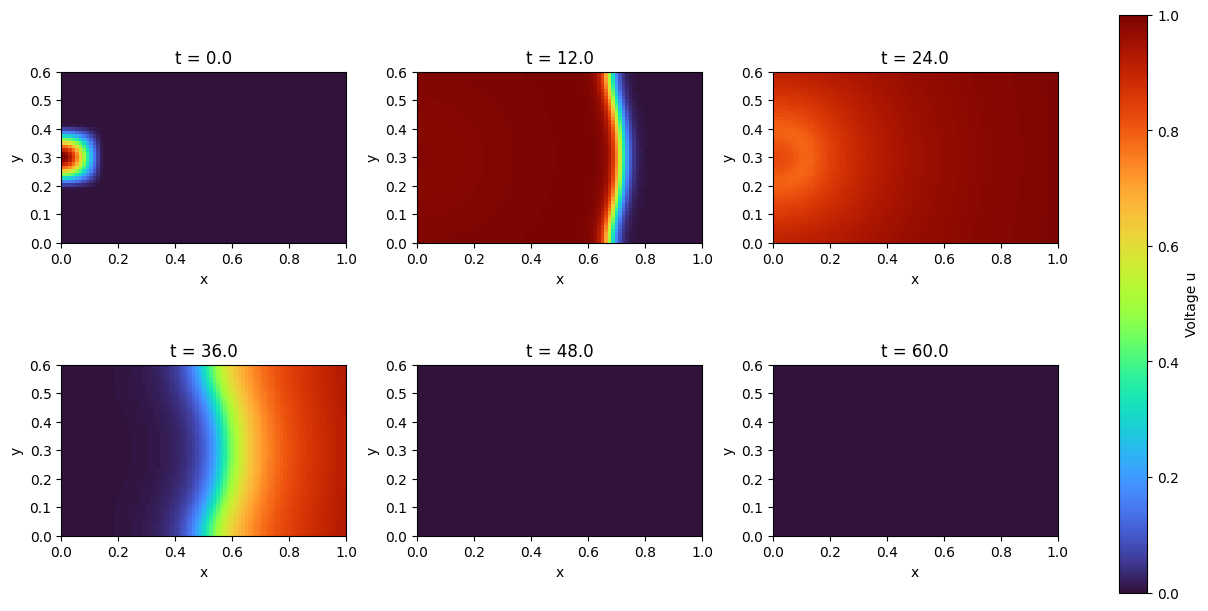

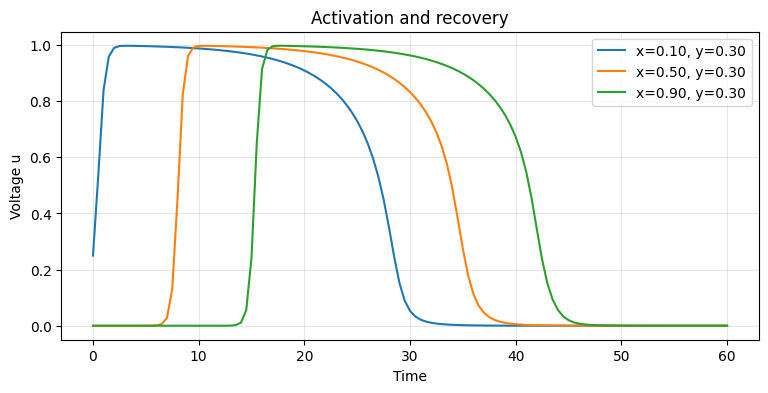

Saved: monodomain_reference.npz


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

# ============================================================
# 1. Geometry and parameters — dimensionless benchmark
# ============================================================
Lx, Ly = 1.0, 0.6
Nx, Ny = 81, 49

D = 0.001

# Aliev–Panfilov parameters
a = 0.05
b = 0.15
k = 8.0
epsilon = 0.002
mu1 = 0.2
mu2 = 0.3

T = 60.0
dt = 0.01
save_every = 50

x = np.linspace(0, Lx, Nx)
y = np.linspace(0, Ly, Ny)
X, Y = np.meshgrid(x, y)

dx = x[1] - x[0]
dy = y[1] - y[0]

# Conservative explicit diffusion time-step check.
# Reaction dynamics also require sufficiently small dt.
dt_limit = 0.45 / (D * (1 / dx**2 + 1 / dy**2))
assert dt <= dt_limit, f"Reduce dt below {dt_limit:.5f}"

# ============================================================
# 2. Initial conditions
# ============================================================
# Localised excitation: smooth compact patch touching left edge.
# No external stimulus is applied after t=0.
patch_width = 0.15
patch_half_height = 0.12

px = np.cos(
    0.5 * np.pi * np.clip(X / patch_width, 0, 1)
)**2

py = np.cos(
    0.5 * np.pi *
    np.clip(np.abs(Y - Ly / 2) / patch_half_height, 0, 1)
)**2

inside = (
    (X < patch_width) &
    (np.abs(Y - Ly / 2) < patch_half_height)
)

u = np.where(inside, px * py, 0.0)
w = np.zeros_like(u)

# ============================================================
# 3. Spatial operator and reaction terms
# ============================================================
def laplacian(u):
    # Reflected ghost nodes:
    # du/dx = 0 at x=0,Lx; du/dy = 0 at y=0,Ly.
    padded = np.pad(u, 1, mode="reflect")

    u_xx = (
        padded[1:-1, 2:]
        - 2 * u
        + padded[1:-1, :-2]
    ) / dx**2

    u_yy = (
        padded[2:, 1:-1]
        - 2 * u
        + padded[:-2, 1:-1]
    ) / dy**2

    return u_xx + u_yy


def rhs(u, w):
    du = (
        D * laplacian(u)
        - k * u * (u - a) * (u - 1)
        - u * w
    )

    dw = (
        epsilon + mu1 * w / (u + mu2)
    ) * (
        -w - k * u * (u - b - 1)
    )

    return du, dw


def rk4_step(u, w, h):
    k1u, k1w = rhs(u, w)

    k2u, k2w = rhs(
        u + 0.5 * h * k1u,
        w + 0.5 * h * k1w
    )

    k3u, k3w = rhs(
        u + 0.5 * h * k2u,
        w + 0.5 * h * k2w
    )

    k4u, k4w = rhs(
        u + h * k3u,
        w + h * k3w
    )

    u_new = u + h / 6 * (k1u + 2*k2u + 2*k3u + k4u)
    w_new = w + h / 6 * (k1w + 2*k2w + 2*k3w + k4w)

    return u_new, w_new

# ============================================================
# 4. Solve and store snapshots
# ============================================================
n_steps = int(np.ceil(T / dt))

times = [0.0]
U = [u.copy()]
W = [w.copy()]

t = 0.0

for step in range(1, n_steps + 1):
    h = min(dt, T - t)
    u, w = rk4_step(u, w, h)
    t += h

    if not np.isfinite(u).all() or not np.isfinite(w).all():
        raise RuntimeError("Solution became unstable. Reduce dt.")

    if step % save_every == 0 or step == n_steps:
        times.append(t)
        U.append(u.copy())
        W.append(w.copy())

times = np.asarray(times)
U = np.stack(U)
W = np.stack(W)

print("Simulation completed")
print("U shape:", U.shape, "→ (time, y, x)")
print(f"Voltage range: {U.min():.4f} to {U.max():.4f}")

# ============================================================
# 5. Voltage snapshots
# ============================================================
indices = np.linspace(0, len(times) - 1, 6).astype(int)

fig, axes = plt.subplots(
    2, 3, figsize=(12, 6),
    constrained_layout=True
)

for ax, index in zip(axes.flat, indices):
    image = ax.imshow(
        U[index],
        origin="lower",
        extent=[0, Lx, 0, Ly],
        cmap="turbo",
        vmin=0,
        vmax=1,
        aspect="equal"
    )
    ax.set_title(f"t = {times[index]:.1f}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")

fig.colorbar(
    image,
    ax=axes.ravel().tolist(),
    label="Voltage u"
)
plt.show()

# ============================================================
# 6. Voltage traces at three locations
# ============================================================
fig, ax = plt.subplots(figsize=(9, 4))

iy = np.argmin(np.abs(y - Ly / 2))

for location in [0.1, 0.5, 0.9]:
    ix = np.argmin(np.abs(x - location))
    ax.plot(
        times, U[:, iy, ix],
        label=f"x={x[ix]:.2f}, y={y[iy]:.2f}"
    )

ax.set_xlabel("Time")
ax.set_ylabel("Voltage u")
ax.set_title("Activation and recovery")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

# ============================================================
# 7. Animation
# ============================================================
fig, ax = plt.subplots(figsize=(8, 4))

image = ax.imshow(
    U[0],
    origin="lower",
    extent=[0, Lx, 0, Ly],
    cmap="turbo",
    vmin=0,
    vmax=1,
    aspect="equal"
)

fig.colorbar(image, ax=ax, label="Voltage u")
ax.set_xlabel("x")
ax.set_ylabel("y")
title = ax.set_title("")


def update(frame):
    image.set_data(U[frame])
    title.set_text(f"Monodomain voltage: t={times[frame]:.1f}")
    return image, title


animation = FuncAnimation(
    fig,
    update,
    frames=len(times),
    interval=80,
    blit=True
)

plt.close(fig)
display(HTML(animation.to_jshtml()))

# ============================================================
# 8. Save numerical data for later PINN comparison
# ============================================================
np.savez_compressed(
    "monodomain_reference.npz",
    x=x,
    y=y,
    t=times,
    u=U,
    w=W
)

print("Saved: monodomain_reference.npz")